# SafeDrive Insurance Ltd. — Insurance Claim Analysis

## Business Understanding

### Business Problem
SafeDrive Insurance Ltd. has observed rising insurance claim payouts. The company wants to identify policyholders who are more likely to file an insurance claim during their policy period.

### Analytical Objective
The objective is to analyse historical insurance policy, policyholder, vehicle and safety-feature data, identify patterns associated with insurance claims, and develop a supervised binary classification model to predict claim likelihood.

### Target Variable
- `is_claim = 0`: No claim filed
- `is_claim = 1`: Claim filed

### Success Metrics

**Business success metrics**

1. **Claim capture rate:** Measure the proportion of actual claims identified within the model's high-risk group. This helps assess whether targeted review could identify potentially costly policies.
2. **High-risk segment lift:** Compare the claim rate in the flagged high-risk group with the overall claim rate to assess whether risk prioritisation is useful.
3. **Investigation efficiency:** Measure how many policies can be prioritised for review while capturing a meaningful proportion of claims.

**Model evaluation metrics**

1. **Recall:** Measures the proportion of actual claims correctly identified; important because missed claims may reduce the usefulness of risk screening.
2. **Precision:** Measures the proportion of predicted claims that are actual claims; useful for understanding how much review effort may be spent on false alarms.
3. **ROC-AUC:** Measures how well the model ranks claim cases above non-claim cases across different classification thresholds.

Because claim outcomes are imbalanced, accuracy alone will not be used to judge model quality. The final model will be selected using validation results and business suitability.

### Expected Business Outcome
Support underwriting and risk management teams through data-driven risk assessment, identification of high-risk segments, and evidence-based recommendations.


### Initial Business Questions
1. Which policyholder, vehicle and safety-related characteristics are associated with higher claim rates?
2. How do claim rates differ across vehicle segments, area clusters and NCAP safety ratings?
3. How accurately can a supervised machine learning model identify policyholders who are likely to file a claim?

### Modelling Approach
Using Logistic Regression as the baseline classification model and compare it with a Decision Tree, as required by the capstone workflow.

In [1]:
import sys
print(sys.executable)

d:\UPGRAD\.venv\Scripts\python.exe


#### 1.0 Loading Important Libraries

In [2]:
import pandas as pd
#from pathlib import Path
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm



#### 1.1 Load the dataset

In [3]:
from pathlib import Path
import pandas as pd

# Look for the source file beside the notebook/current folder, then common upload folder.
candidate_paths = [
    Path(r"D:\UPGRAD\CapStone_Project\dataset.csv"),
    Path.cwd() / "dataset.csv",
    Path("/mnt/data/dataset.csv"),
    Path("/mnt/data/dataset(1).csv")
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "dataset.csv was not found. Place it beside the notebook or in /mnt/data."
    )

insurance = pd.read_csv(DATA_PATH)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Loaded dataset from:", DATA_PATH.resolve())
print("Dataset shape:", insurance.shape)
display(insurance.head(5))

Loaded dataset from: D:\UPGRAD\CapStone_Project\dataset.csv
Dataset shape: (58592, 44)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


#### 1.2 Basic dataset overview

In [4]:

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
column_total=insurance.columns.to_list()
print(len(column_total))
print("list of columns:",column_total)
print(f"Summary of the dataset:{insurance.describe()}\n")
#Mandatory check for duplicates
print(f"\n Duplicate rows:?",insurance[insurance.duplicated(keep=False)])
print("Duplicate policy IDs:", insurance["policy_id"].duplicated().sum())



DATASET OVERVIEW
44
list of columns: ['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder', 'area_cluster', 'population_density', 'make', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'gear_box', 'steering_type', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim']
Summary of the dataset:       policy_tenure    age_of_car  age_of_policyholder  population_density  \
count   58592.000000  58592.000000         58592.000000        58592.000000   
mean        0.611246   

In [5]:
# Dataset dimensions and schema
print("Dataset shape:", insurance.shape)

print("\nData types:")
display(
    insurance.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data_Type")
    .to_frame("Column_Count")
)

print("\nMissing values per column:")
missing_summary = pd.DataFrame({
    "Missing_Count": insurance.isna().sum(),
    "Missing_Percentage": (insurance.isna().mean() * 100).round(2)
})
display(missing_summary)

print("\nExact duplicate rows:", insurance.duplicated().sum())
print("Duplicate policy IDs:", insurance["policy_id"].duplicated().sum())

print("\nTarget counts:")
display(insurance["is_claim"].value_counts(dropna=False).sort_index())

print("\nTarget percentages:")
display(
    (insurance["is_claim"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .sort_index()
)

claim_rate = insurance["is_claim"].mean()
print(f"\nClaim rate: {claim_rate:.2%}")
print(f"No-claim rate: {1 - claim_rate:.2%}")
print(f"Class imbalance ratio (no claim : claim): "
      f"{(insurance['is_claim'].eq(0).sum() / insurance['is_claim'].eq(1).sum()):.2f}:1")
constant_cols = [
    col for col in insurance.columns
    if insurance[col].nunique() <= 1
]

print(f"Number of Constant Columns: {len(constant_cols)}")

display(pd.DataFrame(
    {"Constant_Columns": constant_cols}
))

Dataset shape: (58592, 44)

Data types:


,Column_Count
Data_Type,
object,28
int64,12
float64,4



Missing values per column:


,Missing_Count,Missing_Percentage
policy_id,0,0.0
policy_tenure,0,0.0
age_of_car,0,0.0
age_of_policyholder,0,0.0
area_cluster,0,0.0
population_density,0,0.0
make,0,0.0
segment,0,0.0
model,0,0.0
fuel_type,0,0.0



Exact duplicate rows: 0
Duplicate policy IDs: 0

Target counts:


is_claim
0    54844
1     3748
Name: count, dtype: int64


Target percentages:


is_claim
0    93.6
1     6.4
Name: proportion, dtype: float64


Claim rate: 6.40%
No-claim rate: 93.60%
Class imbalance ratio (no claim : claim): 14.63:1
Number of Constant Columns: 0


,Constant_Columns


### Key Findings:

-Dataset contains 58,592 records and 44 features.
-No missing values were found in the dataset.
-No constant columns were identified, indicating all features contain some variation.

### The target variable (is_claim) is highly imbalanced:

0 (No Claim): 54,844 records (93.6%)
1 (Claim): 3,748 records (6.4%)

### Feature data types:

-28 categorical (string) columns
-12 integer columns
-4 float columns

***policy_id*** has 58,592 unique values: confirming it is an ***identifier*** and not a predictive feature.

#### Several features are binary with only 2 unique values (e.g., safety and vehicle equipment features).
policy_tenure has 58,592 unique values, indicating it behaves like a continuous variable.
No immediate data quality issues were identified; the dataset is ready for detailed exploratory analysis and feature investigation.

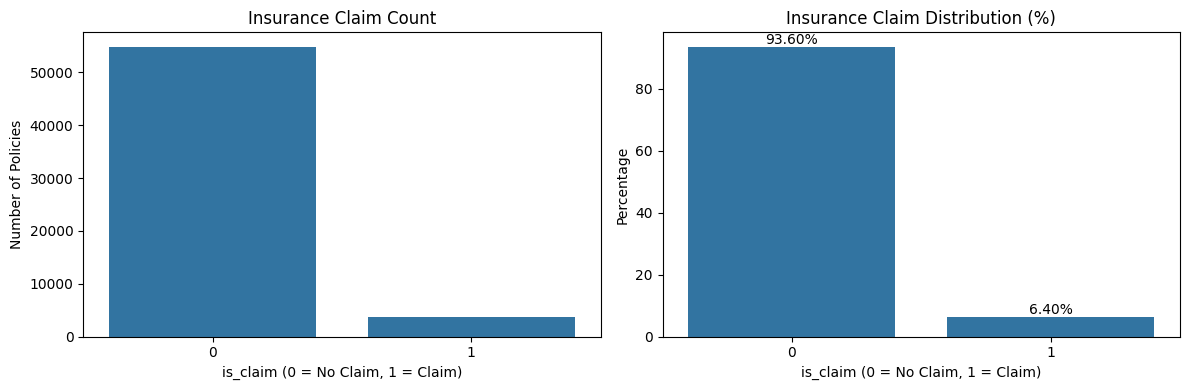

Claim rate: 6.4 %
No-claim rate: 93.6 %


In [6]:
# Target distribution for visual validation check
target_counts = insurance["is_claim"].value_counts().sort_index()
target_pct = (
    insurance["is_claim"]
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)
#A figure creates (the overall canvas), One or more axes (individual plots)
# 1,2 means 1 row and 2 columns in the way how subplots will be arranged side by side
#width = 12
#height = 4
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values,
    ax=axes[0]
)
axes[0].set_title("Insurance Claim Count")
axes[0].set_xlabel("is_claim (0 = No Claim, 1 = Claim)")
axes[0].set_ylabel("Number of Policies")

sns.barplot(
    x=target_pct.index.astype(str),
    y=target_pct.values,
    ax=axes[1]
)
axes[1].set_title("Insurance Claim Distribution (%)")
axes[1].set_xlabel("is_claim (0 = No Claim, 1 = Claim)")
axes[1].set_ylabel("Percentage")
axes[1].bar_label(
    axes[1].containers[0],
    fmt="%.2f%%"
)

plt.tight_layout()
plt.show()

print("Claim rate:", round(target_pct.loc[1], 2), "%")
print("No-claim rate:", round(target_pct.loc[0], 2), "%")

#### 2.1 Univariate EDA for numerical Features: 
##### This analysis helps understand the distribution of each numerical feature and identify whether scaling, transformation, feature engineering, or grouping may be required before model development.

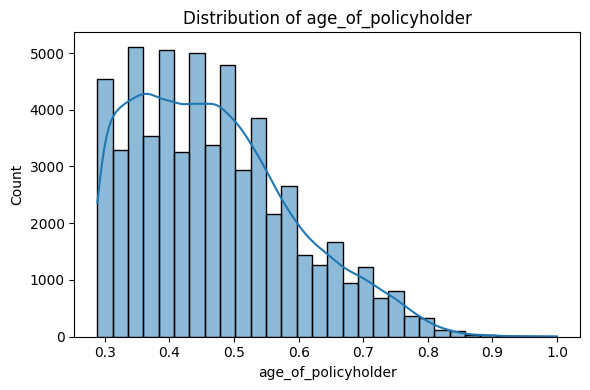

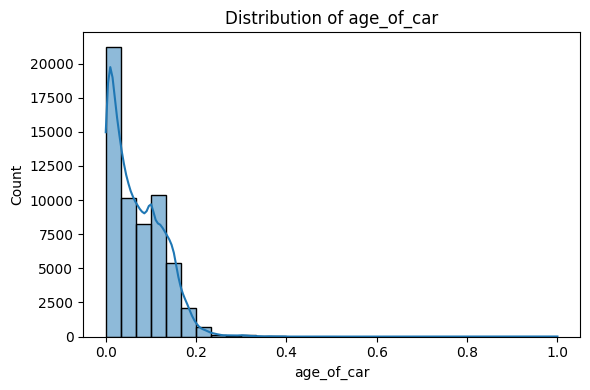

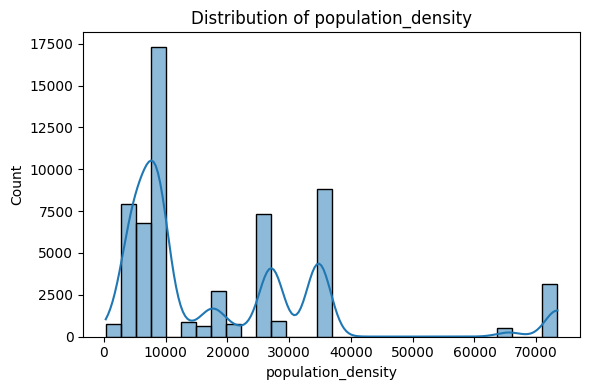

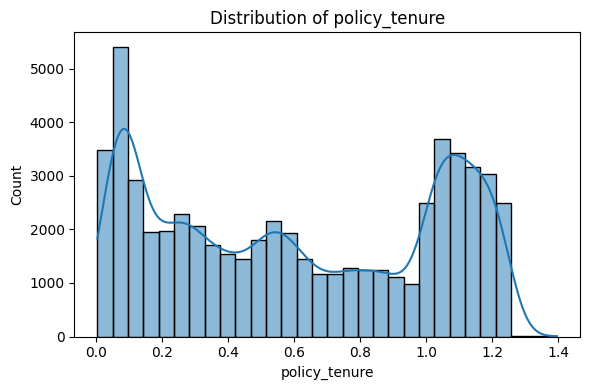

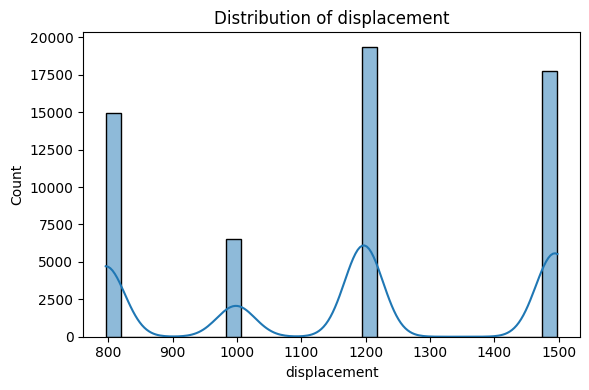

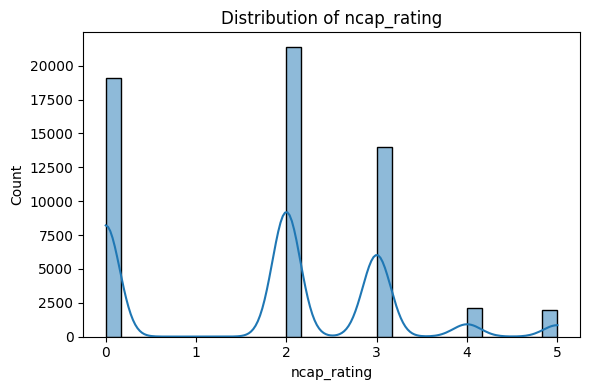

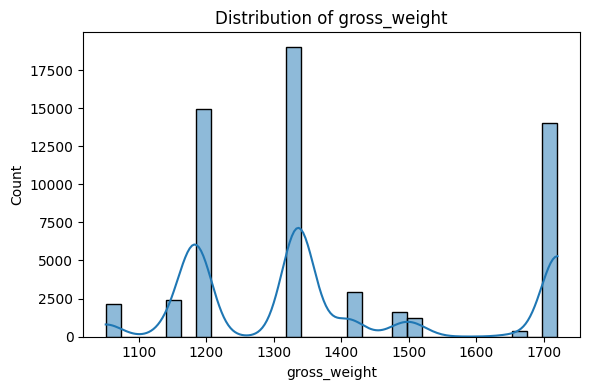

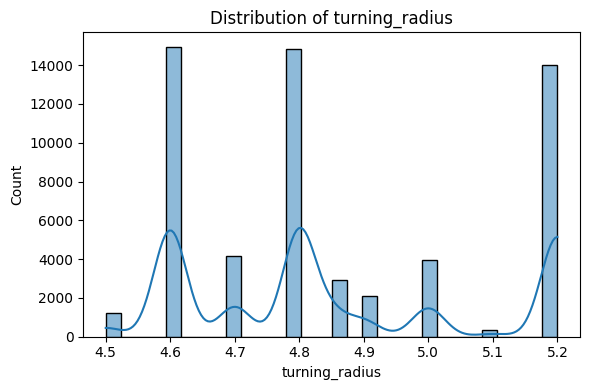

In [7]:
kde_cols = [
    "age_of_policyholder",
    "age_of_car",
    "population_density",
    "policy_tenure",
    "displacement",
    "ncap_rating",
    "gross_weight",
    "turning_radius"
]

for col in kde_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=insurance, x=col, bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

#### 2.2 Univariate EDA for categorical variables
Investigating the distribution of categories. This is important because most of the dataset's descriptive features are categorical.

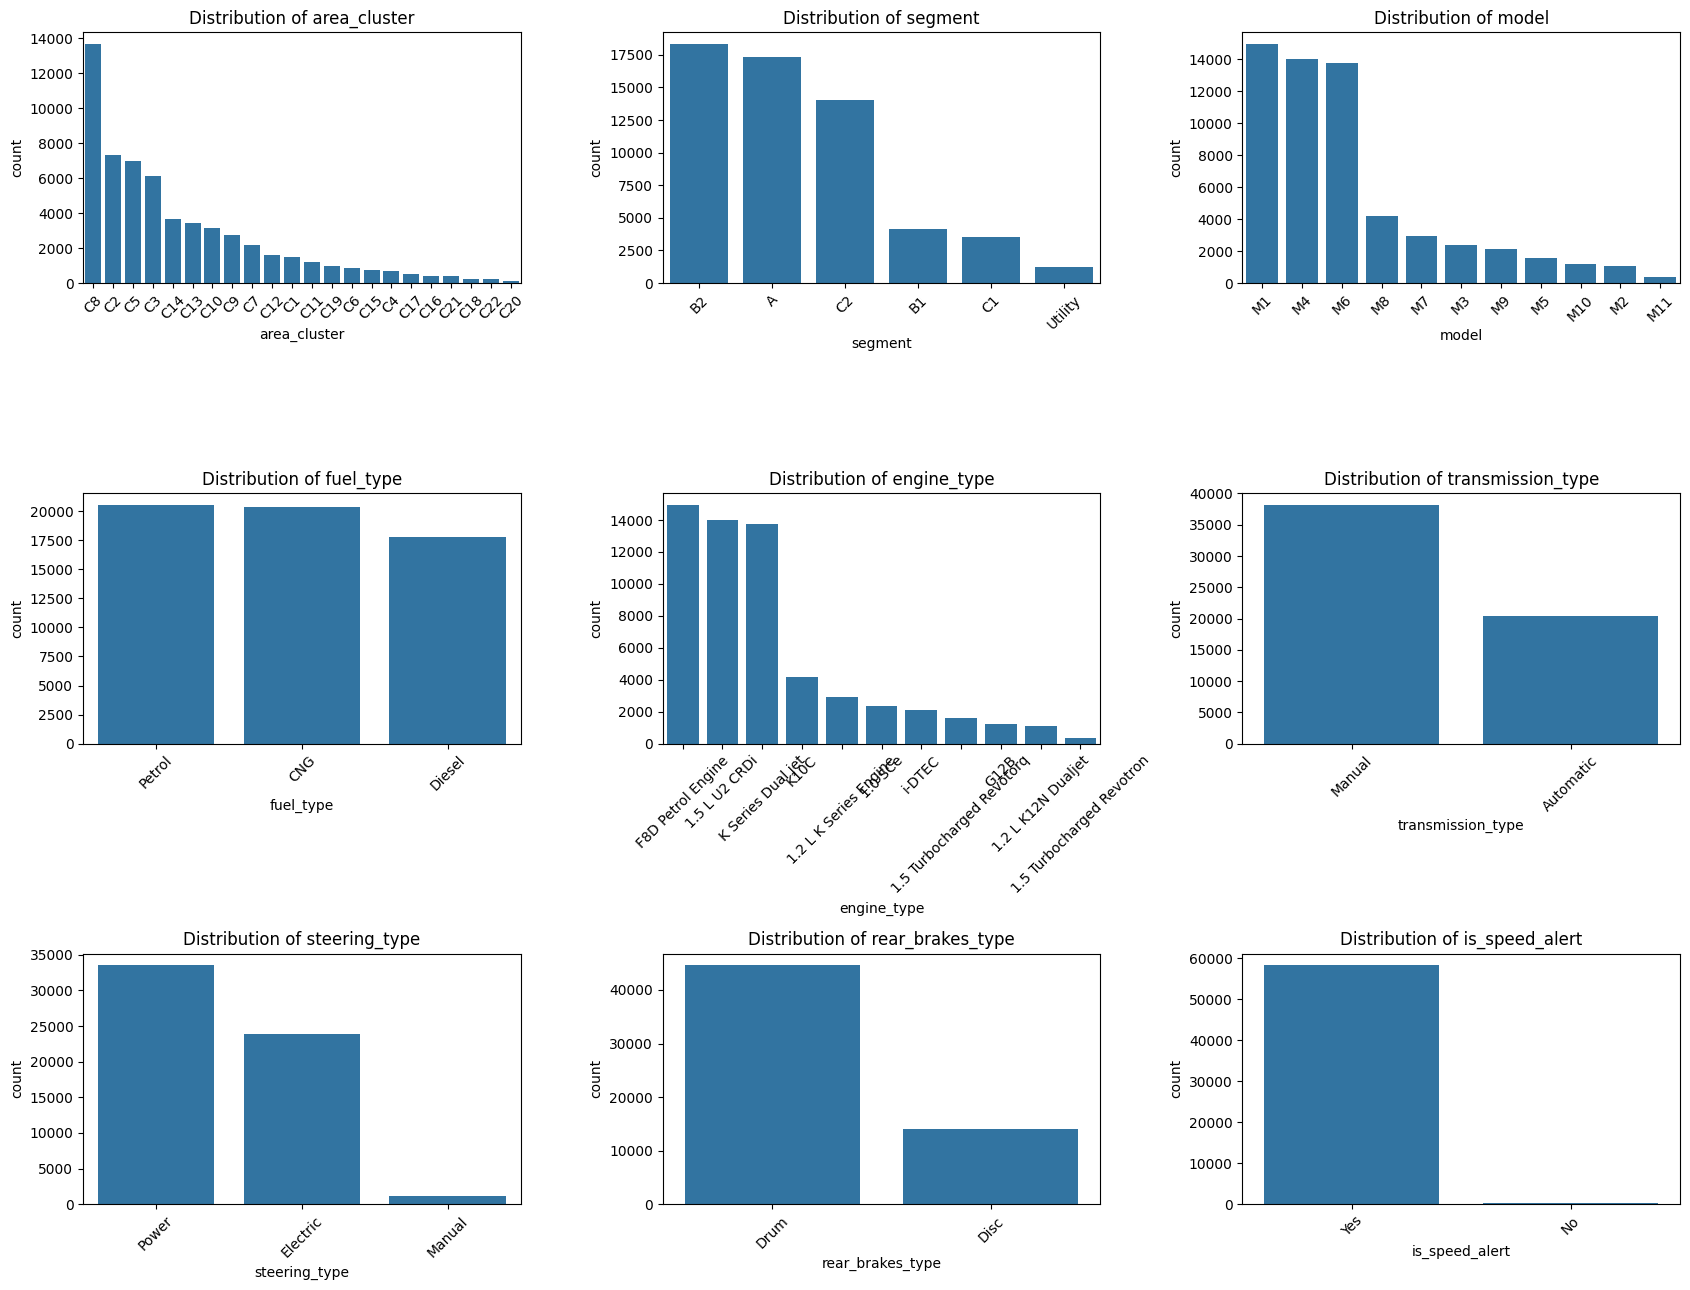

In [8]:

categorical_cols = [
    "area_cluster",
    "segment",
    "model",
    "fuel_type",
    "engine_type",
    "transmission_type",
    "steering_type",
    "rear_brakes_type",
    "is_speed_alert"
]

fig, axes = plt.subplots(3, 3, figsize=(17, 13))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=insurance,
        x=col,
        order=insurance[col].value_counts().index,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#### 2.3 Bivariate EDA for categorical feauters. The claim rate(Binary values) against categorical features is plotted

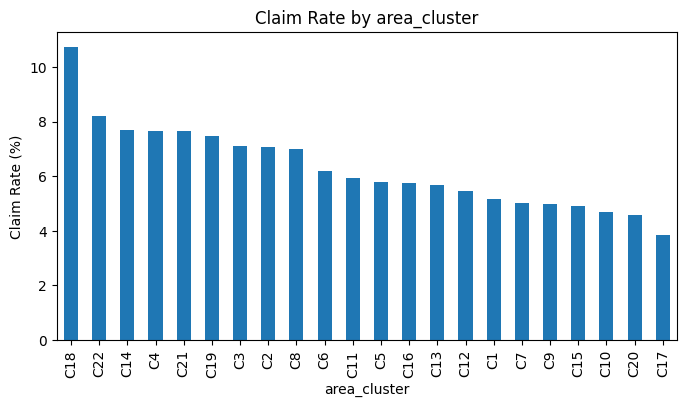

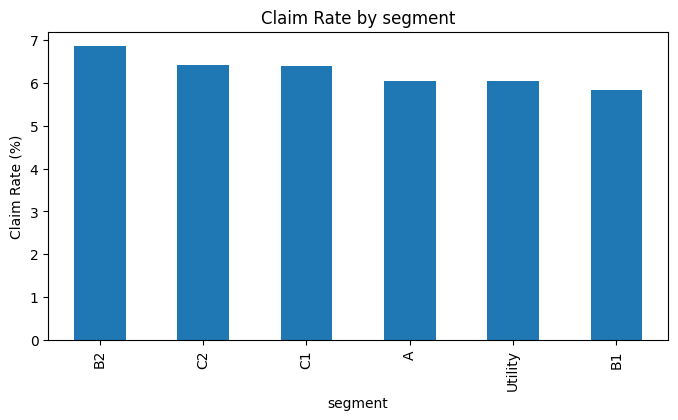

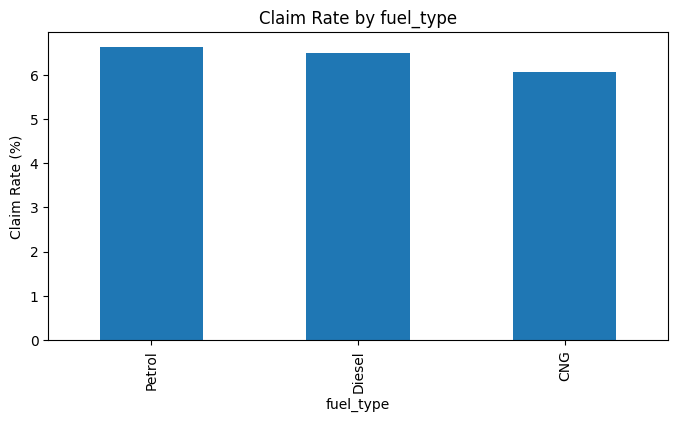

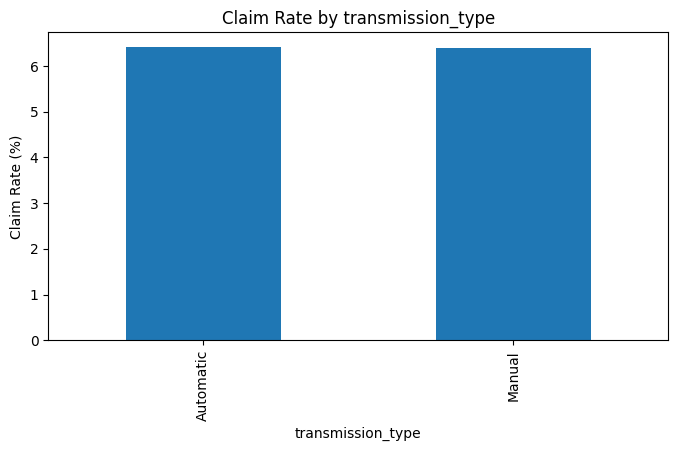

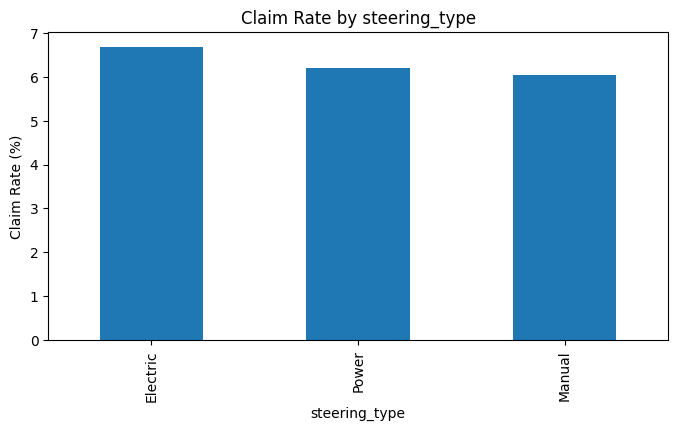

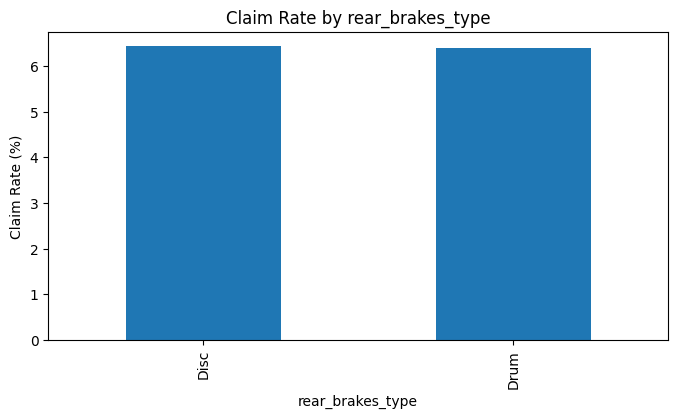

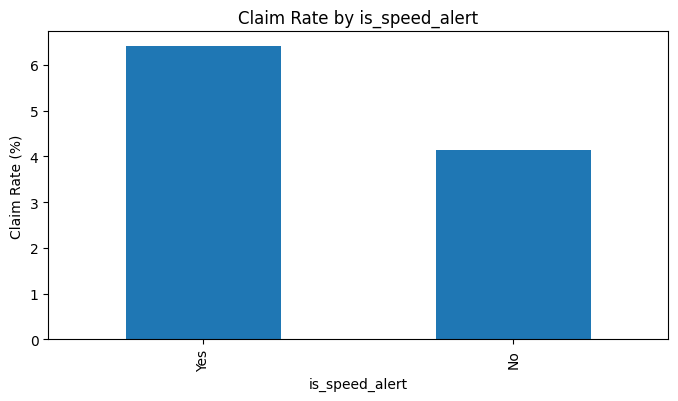

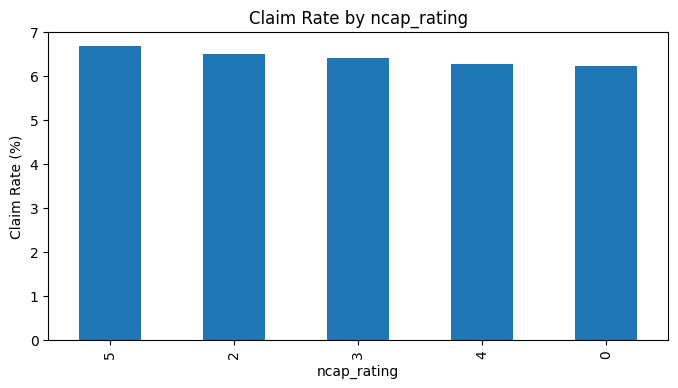

In [9]:
cat_cols = [
    "area_cluster",
    "segment",
    "fuel_type",
    "transmission_type",
    "steering_type",
    "rear_brakes_type",
    "is_speed_alert",
    "ncap_rating"
]
if "policy_id" in cat_cols:
    cat_cols.remove("policy_id")

for col in cat_cols:

    claim_rate = (
        insurance.groupby(col)["is_claim"]
        .mean() * 100
    ).sort_values(ascending=False)

    plt.figure(figsize=(8,4))

    claim_rate.plot(kind="bar")

    plt.title(f"Claim Rate by {col}")
    plt.ylabel("Claim Rate (%)")

    plt.show()


#### 2.4. Bivariate EDA for numerical continuous features (Risk Analysis) against Claim Rates 
Will evaluete how observed claim rates (`is_claim`) shift across key continuous variables.

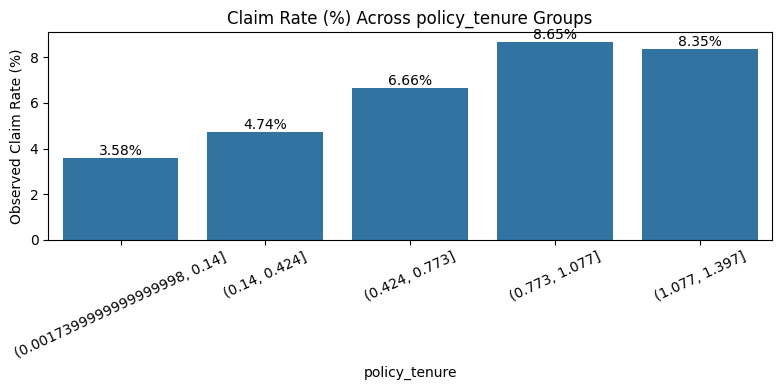

,Total Policies,Claim Rate (%)
policy_tenure,,
"(0.0017399999999999998, 0.14]",11719,3.58
"(0.14, 0.424]",11718,4.74
"(0.424, 0.773]",11718,6.66
"(0.773, 1.077]",11718,8.65
"(1.077, 1.397]",11719,8.35


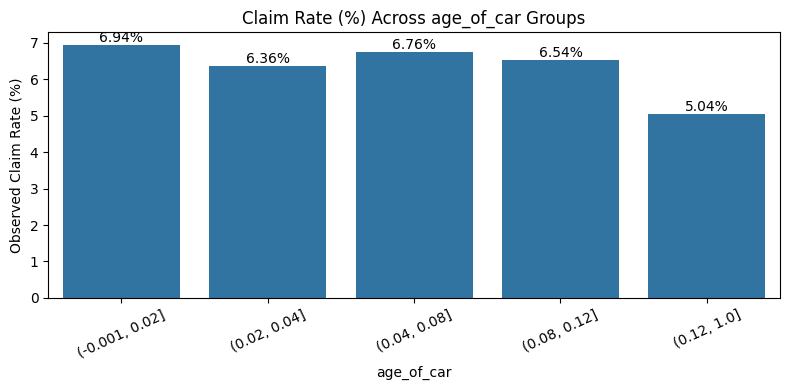

,Total Policies,Claim Rate (%)
age_of_car,,
"(-0.001, 0.02]",16808,6.94
"(0.02, 0.04]",8178,6.36
"(0.04, 0.08]",12013,6.76
"(0.08, 0.12]",10714,6.54
"(0.12, 1.0]",10879,5.04


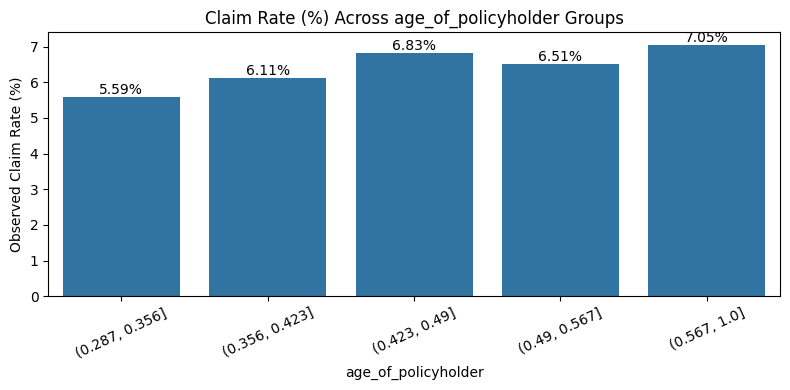

,Total Policies,Claim Rate (%)
age_of_policyholder,,
"(0.287, 0.356]",12932,5.59
"(0.356, 0.423]",11855,6.11
"(0.423, 0.49]",11598,6.83
"(0.49, 0.567]",10530,6.51
"(0.567, 1.0]",11677,7.05


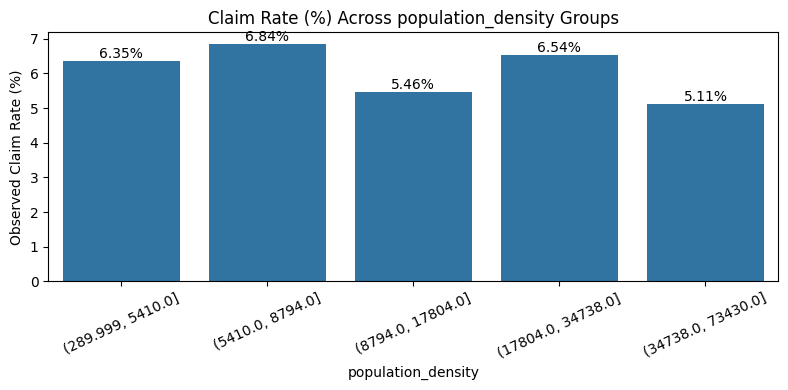

,Total Policies,Claim Rate (%)
population_density,,
"(289.999, 5410.0]",12142,6.35
"(5410.0, 8794.0]",20693,6.84
"(8794.0, 17804.0]",4232,5.46
"(17804.0, 34738.0]",16047,6.54
"(34738.0, 73430.0]",5478,5.11


In [10]:
binned_features = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density",
]

for col in binned_features:
    # 1. Cut the continuous column into 5 equal-sized groups (bins)
    bins = pd.qcut(insurance[col], q=5, duplicates="drop")

    # 2. Multiply 'is_claim' by 100 to plot percentages directly on the y-axis
    plt.figure(figsize=(8, 4))
    ax = sns.barplot(x=bins, y=insurance["is_claim"] * 100, errorbar=None)

    # Optional: Add exact percentage labels on top of each bar
    ax.bar_label(ax.containers[0], fmt="%.2f%%")

    plt.title(f"Claim Rate (%) Across {col} Groups")
    plt.xlabel(col)
    plt.ylabel("Observed Claim Rate (%)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

    # 3. Summary table
    summary = insurance.groupby(bins, observed=True)["is_claim"].agg(
        ["count", "mean"]
    )
    summary["mean"] = (summary["mean"] * 100).round(2)
    summary.columns = ["Total Policies", "Claim Rate (%)"]
    display(summary)

#### 2.5. Feature Engineering

Three business-relevant features are created for further analysis:

- **Safety Equipment Count:** counts the selected binary vehicle safety and monitoring features.
- **Power-to-Weight Ratio:** divides parsed engine power by vehicle gross weight.
- **High Risk Driver Flag:** flags policyholders in the lowest quartile of the provided age feature when the vehicle NCAP rating is 2 or lower.

These are candidate features, not proven predictors. The high-risk flag uses a project-defined rule and will be evaluated during modelling. The safety count includes `is_speed_alert` and `is_ecw`, so it represents a broader safety/monitoring equipment count rather than a pure crash-protection score.

In [11]:
import re

stage1_data = insurance.copy()

# Parse numeric values from the text specifications
stage1_data["max_power_bhp"] = pd.to_numeric(
    stage1_data["max_power"].astype("string")
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

stage1_data["max_torque_nm"] = pd.to_numeric(
    stage1_data["max_torque"].astype("string")
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

# Convert Yes/No safety fields into 1/0
safety_cols = [
    "is_esc", "is_adjustable_steering", "is_tpms",
    "is_parking_sensors", "is_parking_camera",
    "is_front_fog_lights", "is_rear_window_wiper",
    "is_rear_window_washer", "is_rear_window_defogger",
    "is_brake_assist", "is_power_door_locks",
    "is_central_locking", "is_power_steering",
    "is_driver_seat_height_adjustable",
    "is_day_night_rear_view_mirror", "is_ecw",
    "is_speed_alert"
]

for col in safety_cols:
    values = stage1_data[col].astype("string").str.strip().str.lower()
    stage1_data[col] = values.map({
        "yes": 1,
        "no": 0,
        "1": 1,
        "0": 0
    })
# Count selected safety and monitoring features
stage1_data["safety_equipment_count"] = (
    stage1_data[safety_cols].sum(axis=1)
)

# Power-to-weight ratio
stage1_data["power_to_weight"] = (
    stage1_data["max_power_bhp"] /
    stage1_data["gross_weight"].replace(0, np.nan)
)

# Project-defined high-risk flag
age_cutoff = stage1_data["age_of_policyholder"].quantile(0.25)

stage1_data["High_Risk_Driver_Flag"] = (
    (stage1_data["age_of_policyholder"] <= age_cutoff) &
    (stage1_data["ncap_rating"] <= 2)
).astype(int)

print("Dataset shape:", stage1_data.shape)
print("Missing values after feature engineering:",
      stage1_data.isna().sum().sum())

display(
    stage1_data[
        [
            "max_power_bhp",
            "max_torque_nm",
            "safety_equipment_count",
            "power_to_weight",
            "High_Risk_Driver_Flag"
        ]
    ].head()
)

Dataset shape: (58592, 49)
Missing values after feature engineering: 0


,max_power_bhp,max_torque_nm,safety_equipment_count,power_to_weight,High_Risk_Driver_Flag
0,40.36,60.0,3,0.034059,0
1,40.36,60.0,3,0.034059,0
2,40.36,60.0,3,0.034059,0
3,88.5,113.0,14,0.066292,0
4,67.06,91.0,7,0.058061,0


### 2.6. Outlier Investigation and Treatment Plan

Outliers were investigated in continuous numerical features using the Interquartile Range (IQR) method. An observation outside the IQR limits is flagged for review; it is not automatically considered an error.

The original values are retained in the Stage 1 dataset. Any outlier capping or scaling required for modelling will be fitted using the training data only in Stage 2. This avoids using information from the test set during preprocessing.

In [12]:
outlier_cols = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density",
    "turning_radius",
    "length",
    "width",
    "height",
    "gross_weight",
    "displacement"
]

outlier_rows = []

for col in outlier_cols:
    q1 = stage1_data[col].quantile(0.25)
    q3 = stage1_data[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (stage1_data[col] < lower) |
        (stage1_data[col] > upper)
    ).sum()

    outlier_rows.append({
        "Feature": col,
        "Lower_Limit": round(lower, 3),
        "Upper_Limit": round(upper, 3),
        "Potential_Outliers": int(count)
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Feature,Lower_Limit,Upper_Limit,Potential_Outliers
0,policy_tenure,-1.033,2.282,0
1,age_of_car,-0.115,0.245,269
2,age_of_policyholder,0.091,0.822,221
3,population_density,-25224.500,58339.500,3647
4,turning_radius,4.000,5.600,0
5,length,2620.000,4820.000,0
6,width,1155.000,2115.000,0
7,height,1235.000,1875.000,0
8,gross_weight,697.500,1997.500,0
9,displacement,-249.500,2538.500,0


#### 2.7. Correlation Analysis and Multicollinearity Check

Correlation analysis is used to examine relationships among numerical features and their individual associations with the claim outcome. Variance Inflation Factor (VIF) is then used to assess multicollinearity among the shortlisted numerical predictors.

A high VIF indicates that a feature may overlap with other predictors. VIF does not measure predictive power, and it does not by itself determine whether a feature should be retained. Final feature usefulness will be assessed during Stage 2 model validation.

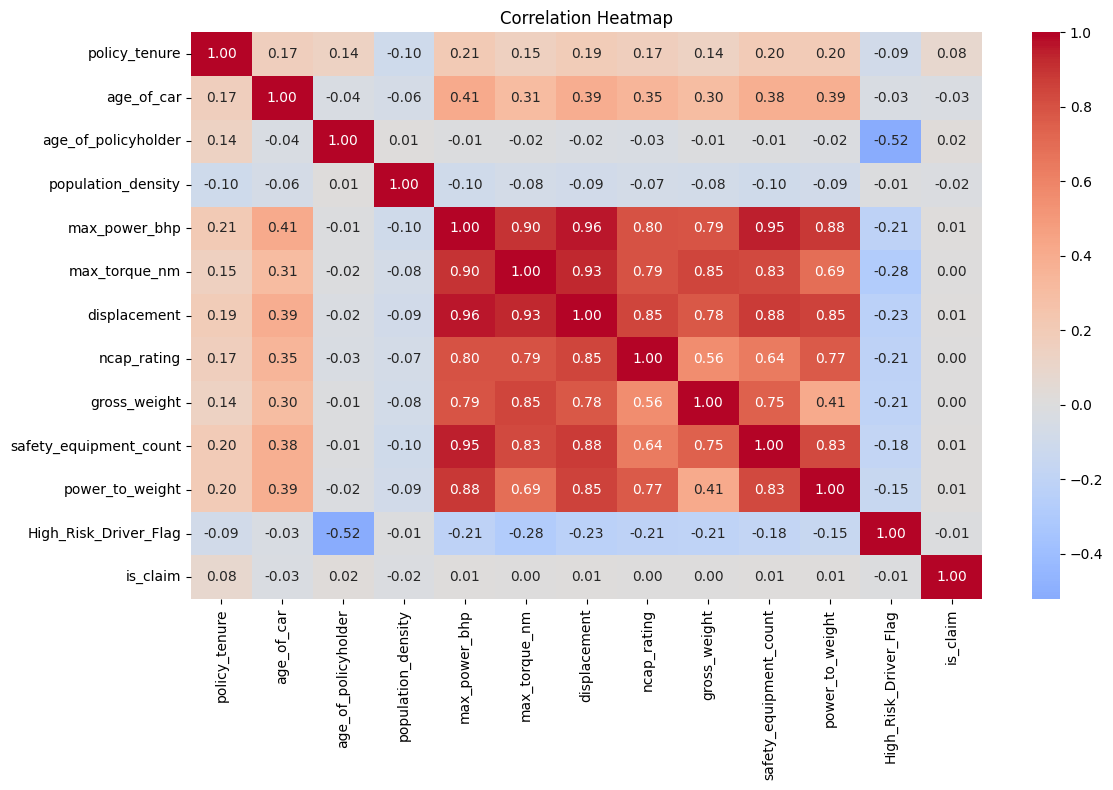

,Correlation_with_is_claim
policy_tenure,0.078747
age_of_car,-0.028172
age_of_policyholder,0.022435
population_density,-0.017808
High_Risk_Driver_Flag,-0.013904
safety_equipment_count,0.008448
power_to_weight,0.008260
max_power_bhp,0.007698
displacement,0.007678
max_torque_nm,0.004294


In [13]:
corr_cols = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density",
    "max_power_bhp",
    "max_torque_nm",
    "displacement",
    "ncap_rating",
    "gross_weight",
    "safety_equipment_count",
    "power_to_weight",
    "High_Risk_Driver_Flag",
    "is_claim"
]

corr_data = stage1_data[corr_cols].copy()
corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Show individual correlations with the target
target_corr = (
    corr_matrix["is_claim"]
    .drop("is_claim")
    .sort_values(key=abs, ascending=False)
)

display(target_corr.to_frame("Correlation_with_is_claim"))

#### Multicollinearity identification criteria:
1) ***VIF below 5: generally acceptable for this screening exercise.***
2) ***VIF from 5 to 10: investigate potential overlap.***
3) ***VIF above 10: stronger evidence of multicollinearity requiring review.***

In [14]:


vif_features = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density",
    "power_to_weight",
    "safety_equipment_count"
]

vif_data = stage1_data[vif_features].dropna()

X_scaled = StandardScaler().fit_transform(vif_data)
X_vif = sm.add_constant(X_scaled)

vif_results = pd.DataFrame({
    "Feature": vif_features,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(1, X_vif.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(vif_results)

,Feature,VIF
4,power_to_weight,3.331158
5,safety_equipment_count,3.320190
1,age_of_car,1.204736
0,policy_tenure,1.088097
2,age_of_policyholder,1.026145
3,population_density,1.017031


#### Feature Selection Rationale

Features are retained as candidates based on business relevance, data quality, interpretability, and multicollinearity checks. Their actual predictive value will be assessed using validation metrics in Stage 2.

The `policy_id` column is retained for traceability but excluded from model predictors. The target `is_claim` is used only as the outcome variable. The `High_Risk_Driver_Flag` is an exploratory feature based on a project-defined rule and is not automatically assumed to improve the model.

In [15]:
feature_review = pd.DataFrame([
    {
        "Feature": "policy_tenure",
        "Reason": "Represents policy tenure and may relate to claim patterns.",
        "Decision": "Candidate predictor"
    },
    {
        "Feature": "age_of_car",
        "Reason": "Captures vehicle age, which may relate to risk.",
        "Decision": "Candidate predictor"
    },
    {
        "Feature": "age_of_policyholder",
        "Reason": "Captures the supplied policyholder age feature.",
        "Decision": "Candidate predictor"
    },
    {
        "Feature": "population_density",
        "Reason": "Provides an area-level context for risk analysis.",
        "Decision": "Candidate predictor"
    },
    {
        "Feature": "power_to_weight",
        "Reason": "Combines parsed engine power and vehicle weight.",
        "Decision": "Candidate predictor; check overlap"
    },
    {
        "Feature": "safety_equipment_count",
        "Reason": "Summarises selected safety and monitoring equipment.",
        "Decision": "Candidate predictor"
    },
    {
        "Feature": "High_Risk_Driver_Flag",
        "Reason": "Flags a project-defined age and NCAP combination.",
        "Decision": "Exploratory; validate in Stage 2"
    },
    {
        "Feature": "policy_id",
        "Reason": "Unique identifier, not a risk characteristic.",
        "Decision": "Exclude from predictors"
    },
    {
        "Feature": "is_claim",
        "Reason": "Outcome the model must predict.",
        "Decision": "Target only"
    }
])

display(feature_review)

,Feature,Reason,Decision
0,policy_tenure,Represents policy tenure and may relate to cla...,Candidate predictor
1,age_of_car,"Captures vehicle age, which may relate to risk.",Candidate predictor
2,age_of_policyholder,Captures the supplied policyholder age feature.,Candidate predictor
3,population_density,Provides an area-level context for risk analysis.,Candidate predictor
4,power_to_weight,Combines parsed engine power and vehicle weight.,Candidate predictor; check overlap
5,safety_equipment_count,Summarises selected safety and monitoring equi...,Candidate predictor
6,High_Risk_Driver_Flag,Flags a project-defined age and NCAP combination.,Exploratory; validate in Stage 2
7,policy_id,"Unique identifier, not a risk characteristic.",Exclude from predictors
8,is_claim,Outcome the model must predict.,Target only


In [16]:
# One final check for any infinite values
numeric_cols = stage1_data.select_dtypes(include="number").columns

print(
    "Infinite numeric values:",
    np.isinf(stage1_data[numeric_cols]).sum().sum()
)

Infinite numeric values: 0


#### Final Data Quality Checks and Stage 1 Export

Before completing Stage 1, the dataset is checked for duplicate records, missing values, target validity, identifier uniqueness, and the presence of engineered features.

The exported dataset retains `policy_id` for record traceability and `is_claim` as the target. `policy_id` must be excluded from the predictor set during modelling. Categorical encoding, scaling, and any learned imputation will be fitted on the training data in Stage 2 to prevent data leakage.

In [17]:
# ============================================================
# Final Validation and Export
# ============================================================

print("Dataset Shape:", stage1_data.shape)
print("Missing Values:", stage1_data.isnull().sum().sum())
print("Duplicate Rows:", stage1_data.duplicated().sum())

print("\nTarget Distribution:")
display(stage1_data["is_claim"].value_counts())

# Check engineered features
engineered_features = [
    "max_power_bhp",
    "max_torque_nm",
    "safety_equipment_count",
    "power_to_weight",
    "High_Risk_Driver_Flag"
]

print("\nEngineered Features Summary:")
display(
    stage1_data[engineered_features]
    .describe()
    .round(2)
)

# Simple validation
assert stage1_data.isnull().sum().sum() == 0
assert stage1_data.duplicated().sum() == 0

print("\nValidation Passed Successfully.")

# ============================================================
# Export Clean Dataset
# ============================================================

stage1_data.to_csv(
    "insurance_stage1_cleaned.csv",
    index=False
)

print("insurance_stage1_cleaned.csv exported successfully.")

# ============================================================
# Save Selected Modeling Features
# ============================================================

baseline_features = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density"
]

pd.DataFrame(
    {"Feature": baseline_features}
).to_csv(
    "stage1_baseline_feature_candidates.csv",
    index=False
)

print("stage1_baseline_feature_candidates.csv exported successfully.")

Dataset Shape: (58592, 49)
Missing Values: 0
Duplicate Rows: 0

Target Distribution:


is_claim
0    54844
1     3748
Name: count, dtype: int64


Engineered Features Summary:


,max_power_bhp,max_torque_nm,safety_equipment_count,power_to_weight,High_Risk_Driver_Flag
count,58592.0,58592.0,58592.00,58592.0,58592.00
mean,78.98,134.45,9.68,0.06,0.17
std,27.7,73.15,5.15,0.02,0.38
min,40.36,60.0,2.00,0.03,0.00
25%,40.36,60.0,3.00,0.03,0.00
50%,88.5,113.0,11.00,0.07,0.00
75%,97.89,200.0,16.00,0.07,0.00
max,118.36,250.0,16.00,0.09,1.00



Validation Passed Successfully.
insurance_stage1_cleaned.csv exported successfully.
stage1_baseline_feature_candidates.csv exported successfully.
